# **Прикладные задачи МО на графах (версия для магистров). 10.09.2025**

## **Метрики узлов  в графе**

Библиотека для работы с графами [NetworkX](https://networkx.org/documentation/stable/)

Руководство [Tutorial](https://networkx.org/documentation/stable/tutorial.html)

In [1]:
# Импортируем библиотеку для работы с графами и не только
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy import linalg as LA

## Анализ графа

Для примера возьмем известный датасет - граф дружбы карате клуба [Karate Club Network](https://en.wikipedia.org/wiki/Zachary%27s_karate_club).

In [61]:
# граф карате клуба
G = nx.karate_club_graph()

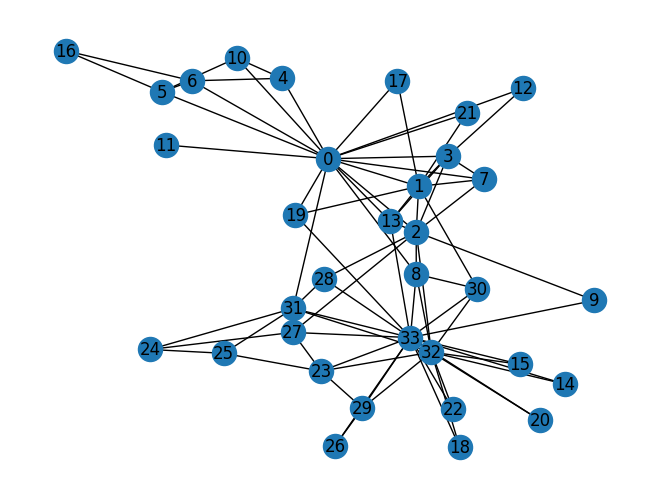

In [3]:
# Визуализация
nx.draw(G, with_labels = True)

In [4]:
# Ориентированный или нет
nx.is_directed(G)

False

In [5]:
# Число узлов, число рёбер
num_nodes = G.number_of_nodes()
num_edges = G.number_of_edges()

print(f'Число узлов: {num_nodes}', f'Число ребер: {num_edges}', sep='\n')

Число узлов: 34
Число ребер: 78


In [6]:
# Связный ли граф
nx.is_connected(G)

True

In [7]:
# Степени вершин
G_node_degrees = [degree[1] for degree in G.degree()]

In [8]:
print(f'Минимальная степень узла: {np.min(G_node_degrees)}',
      f'Максимальная степень узла: {np.max(G_node_degrees)}',
      f'Средняя степень узла: {np.mean(G_node_degrees): .6f}', sep='\n')

Минимальная степень узла: 1
Максимальная степень узла: 17
Средняя степень узла:  4.588235


In [9]:
# средняя степень узла (проверка)
avg_degree = np.sum(G_node_degrees)/num_nodes

print(f'Средняя степень узла: {avg_degree}')

Средняя степень узла: 4.588235294117647


In [10]:
# Радиус и диаметр графа
rad = nx.radius(G)
diam = nx.diameter(G)

print(f'Радиус графа {rad}',
      f'Диаметр графа {diam}',  sep='\n')


Радиус графа 3
Диаметр графа 5


## Кластерный коэффициент

*Локальный кластерный коэффициент* (узла) (local clustering coefficient) - доля соседей узла, соединенных ребром

$$ C_i=\frac{L_i}{C_{k_i}^2} = \frac{2 L_i}{k_i(k_i-1)},$$

где  $k_i = \deg(v_i)$ --- степень узла, $L_i$ --- число связей между соседями узла $i$.


$C_i$ - вероятность того, что два соседа узла $i$ соединены ребром между собой.

*Средний кластерный коэффициент*

$$ \langle C \rangle=\frac{1}{n}\sum_{i=1}^{n}C_i $$

$\langle C \rangle$ --- вероятность того, что два соседа случайно выбранного узла сети связаны между собой.

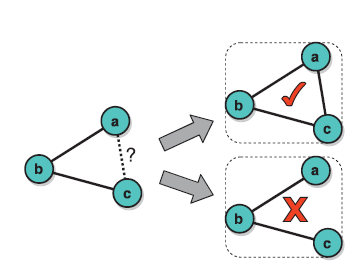

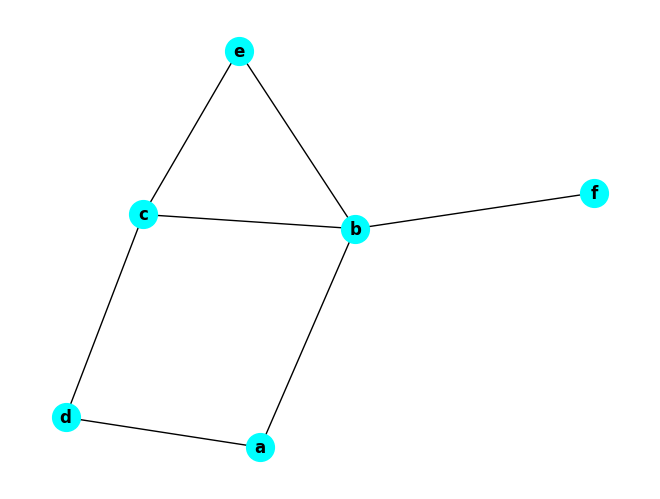

In [11]:
# Создадим неорграф
H = nx.Graph()
H.add_edges_from([("a","b"),("a","d"),("b","c"),("b","e"),
("b","f"),("c","d"),("c","e")])
nx.draw(H, node_size=400, node_color='cyan', with_labels=True, font_weight='bold')


In [12]:
# Подсчитаем кластерный коэффициент для узла b
# Cтепень узла b
k_b = H.degree['b']

# Соседи узла b
neighbors_b = list(H.adj['b'])

# Индуцированный подграф на вершинах-соседях b
subgr_H = nx.induced_subgraph(H, neighbors_b)

# Число рёбер между соседями и
L_b = nx.number_of_edges(subgr_H)

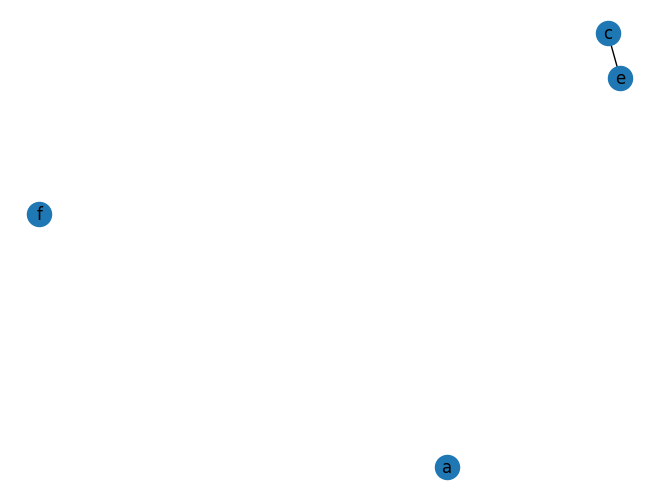

In [13]:
nx.draw(subgr_H, with_labels = True)

In [14]:
# Кластерный коэффициент для узла b

2*L_b/(k_b * (k_b - 1))

0.16666666666666666

In [15]:
# Кластерные коэффициенты всех вершин графа H
nx.clustering(H)

{'a': 0,
 'b': 0.16666666666666666,
 'd': 0,
 'c': 0.3333333333333333,
 'e': 1.0,
 'f': 0}

In [16]:
# Локальные кластерные коэффициенты графа карате клуба
cl_coeff = nx.clustering(G)
cl_coeff

{0: 0.15,
 1: 0.3333333333333333,
 2: 0.24444444444444444,
 3: 0.6666666666666666,
 4: 0.6666666666666666,
 5: 0.5,
 6: 0.5,
 7: 1.0,
 8: 0.5,
 9: 0,
 10: 0.6666666666666666,
 11: 0,
 12: 1.0,
 13: 0.6,
 14: 1.0,
 15: 1.0,
 16: 1.0,
 17: 1.0,
 18: 1.0,
 19: 0.3333333333333333,
 20: 1.0,
 21: 1.0,
 22: 1.0,
 23: 0.4,
 24: 0.3333333333333333,
 25: 0.3333333333333333,
 26: 1.0,
 27: 0.16666666666666666,
 28: 0.3333333333333333,
 29: 0.6666666666666666,
 30: 0.5,
 31: 0.2,
 32: 0.19696969696969696,
 33: 0.11029411764705882}

Text(0, 0.5, 'Число узлов')

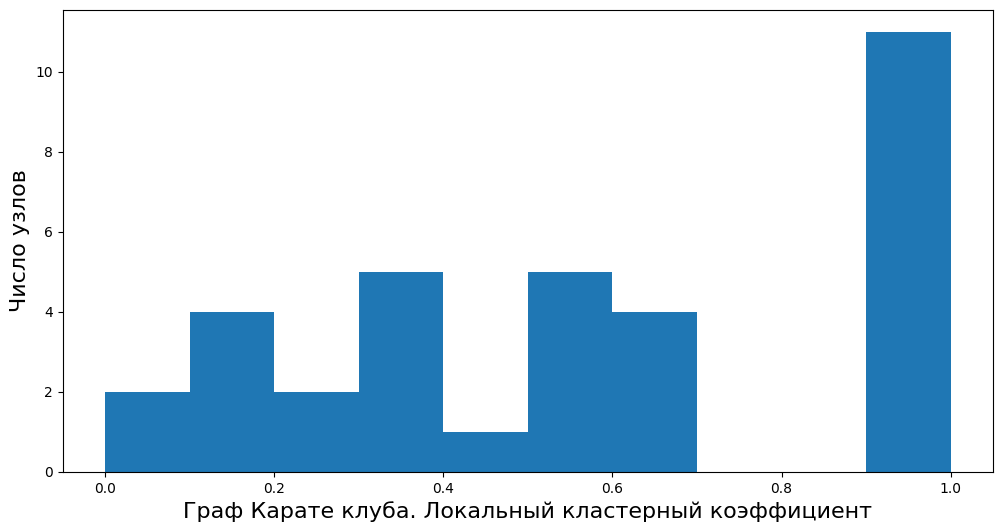

In [17]:
# Визуализируем полученные значения лок. кластерного коэффициента
plt.figure(figsize=(12, 6))
plt.hist(nx.clustering(G).values(), bins=10)
plt.xlabel("Граф Карате клуба. Локальный кластерный коэффициент", fontdict={"size": 16})
plt.ylabel("Число узлов", fontdict={"size": 16})

In [18]:
# средний кластерный коэффициент
nx.average_clustering(G)

0.5706384782076823

## Меры центральности

**Центральность по степени** (нормализованная)

$$C_D(v) = \frac{\deg(v)}{n-1}.$$

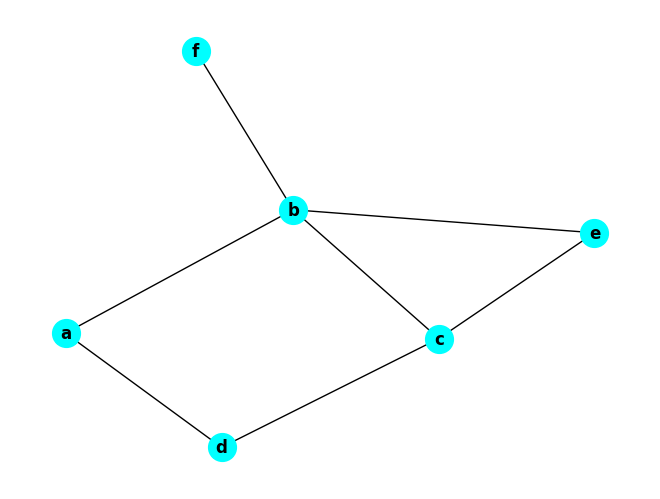

In [19]:
# Граф H

nx.draw(H, node_size=400, node_color='cyan', with_labels=True, font_weight='bold')

In [20]:
H_degree_centrality = [degree[1] * (1/5) for degree in H.degree()]
H_degree_centrality

[0.4, 0.8, 0.4, 0.6000000000000001, 0.4, 0.2]

In [21]:
nx.degree_centrality(H)

{'a': 0.4, 'b': 0.8, 'd': 0.4, 'c': 0.6000000000000001, 'e': 0.4, 'f': 0.2}

In [22]:
# Центральность по степени графа Карате клуба
degree_centrality = nx.degree_centrality(G)

# сортируем и выводим первые 8
(sorted(degree_centrality.items(), key=lambda item: item[1], reverse=True))[:8]

[(33, 0.5151515151515151),
 (0, 0.48484848484848486),
 (32, 0.36363636363636365),
 (2, 0.30303030303030304),
 (1, 0.2727272727272727),
 (3, 0.18181818181818182),
 (31, 0.18181818181818182),
 (8, 0.15151515151515152)]

In [23]:
# сортируем вершины по степени
# действительно, те же самые вершины

(sorted(G.degree, key=lambda item: item[1], reverse=True))[:8]

[(33, 17), (0, 16), (32, 12), (2, 10), (1, 9), (3, 6), (31, 6), (8, 5)]

Text(0, 0.5, 'Число вершин')

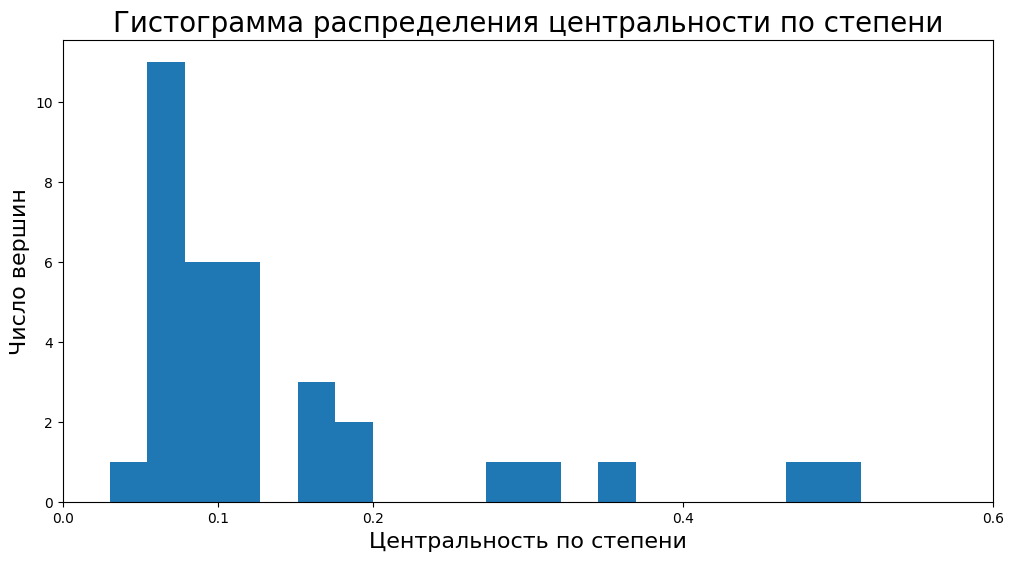

In [24]:
# Гистограмма
plt.figure(figsize=(12, 6))
plt.hist(degree_centrality.values(), bins=20)
plt.xticks(ticks=[0, 0.1, 0.2, 0.4, 0.6])  # метки по оси ОХ
plt.title("Гистограмма распределения центральности по степени", fontdict={"size": 20}, loc="center")
plt.xlabel("Центральность по степени", fontdict={"size": 16})
plt.ylabel("Число вершин", fontdict={"size": 16})

(np.float64(-1.1819180627731938),
 np.float64(0.9144710415655142),
 np.float64(-0.806764373734844),
 np.float64(0.8626471735585174))

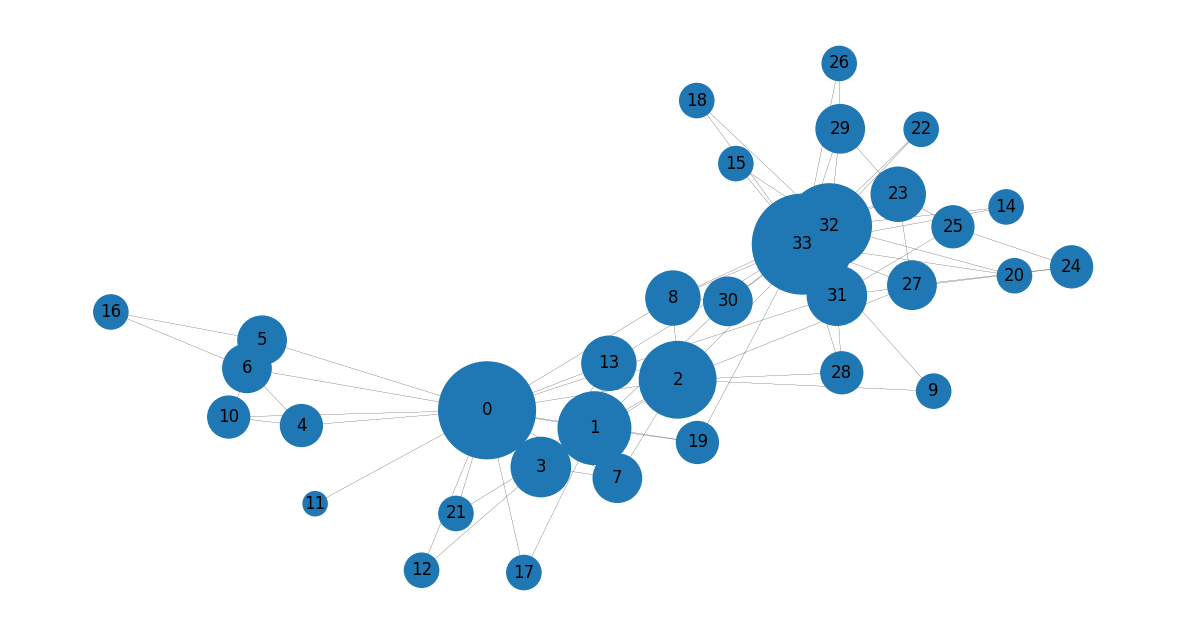

In [25]:
# попытка нарисовать красивую картинку
node_size = [v * 10000 for v in degree_centrality.values()]
plt.figure(figsize=(15, 8))
nx.draw_networkx(G, node_size=node_size, with_labels=True, width=0.15)
plt.axis("off")

**Центральность по близости** - средняя длина кратчайшего пути от вершины до всех остальных.

$$ C_C(u) = \frac{n - 1}{\sum_{v=1}^{n-1} d(u, v)}, $$

где  $d(v, u)$ длина кратчайшего пути между $u$ и $v$.

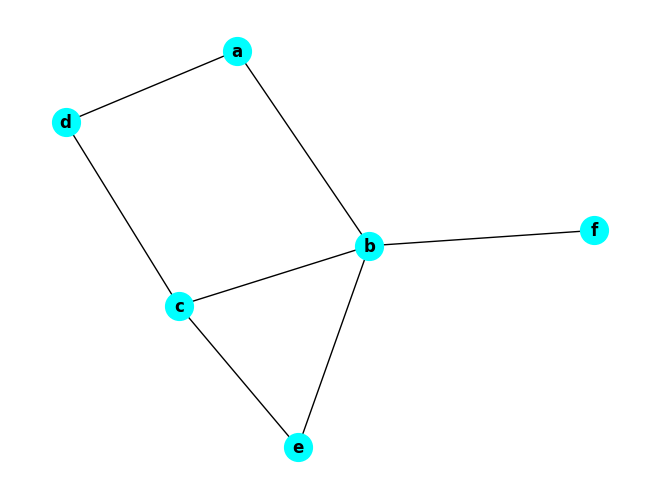

In [26]:
# Граф H

nx.draw(H, node_size=400, node_color='cyan', with_labels=True, font_weight='bold')

In [27]:
# Длины кратчайших путей от вершины a
nx.shortest_path_length(H, source = 'a')

{'a': 0, 'b': 1, 'd': 1, 'c': 2, 'e': 2, 'f': 2}

In [28]:
# Центральность по близости для вершины a
shortest_path_lengths_a = nx.shortest_path_length(H, source = 'a')

5/(sum(shortest_path_lengths_a.values()))

0.625

In [29]:
nx.centrality.closeness_centrality(H)

{'a': 0.625,
 'b': 0.8333333333333334,
 'd': 0.5555555555555556,
 'c': 0.7142857142857143,
 'e': 0.625,
 'f': 0.5}

In [30]:
# Центральность по близости  для графа Карате клуба
closeness_centrality = nx.centrality.closeness_centrality(G)

(sorted(closeness_centrality.items(), key=lambda item: item[1], reverse=True))[:8]

[(0, 0.5689655172413793),
 (2, 0.559322033898305),
 (33, 0.55),
 (31, 0.5409836065573771),
 (8, 0.515625),
 (13, 0.515625),
 (32, 0.515625),
 (19, 0.5)]

(np.float64(-1.2063457303361254),
 np.float64(1.171543162108746),
 np.float64(-1.1494372549295093),
 np.float64(0.912521576830857))

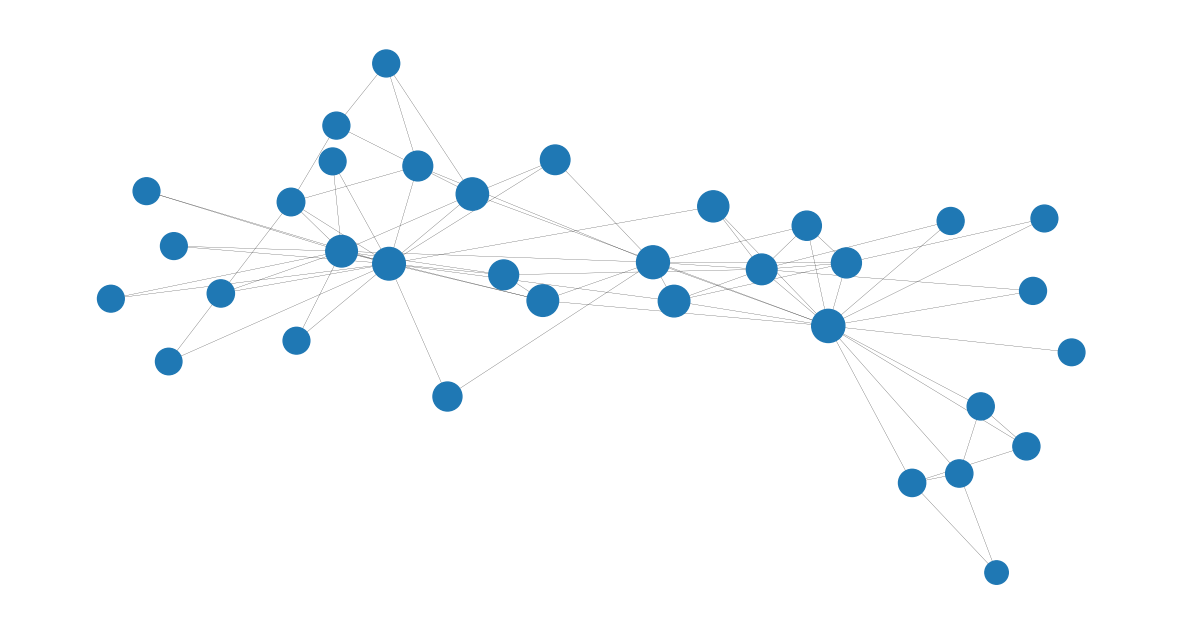

In [31]:
# Визуализация
node_size = [v * 1000 for v in closeness_centrality.values()]
plt.figure(figsize=(15, 8))
nx.draw_networkx(G, node_size=node_size, with_labels=False, width=0.15)
plt.axis("off")

**Центральность по посредничеству**

$$ c_B(v) =\sum_{s,t \in V} \frac{\sigma(s, t|v)}{\sigma(s, t)}, $$

 $\sigma(s, t)$ число кратчайших $(s, t)$-путей, $\sigma(s, t|v)$ число кратчайших $(s, t)$-путей, проходящих через вершину  $v\neq s \neq t$.

Полагаем, что  $s = t$, $\sigma(s, t) = 1$, и для  $v \in \{s, t\}$, $\sigma(s, t|v) = 0$.

Значения центральности по посредничеству можно нормировать, домножив на $2/((n-1)(n-2))$ для неорграфов .

In [32]:
# Центральность по посредничеству (ненормированная)
nx.centrality.betweenness_centrality(H, normalized = False)

{'a': 1.0, 'b': 5.5, 'd': 0.5, 'c': 2.0, 'e': 0.0, 'f': 0.0}

In [33]:
# Нормированная центральность по посредничеству
nx.centrality.betweenness_centrality(H)

{'a': 0.1, 'b': 0.55, 'd': 0.05, 'c': 0.2, 'e': 0.0, 'f': 0.0}

In [34]:
# Центральность по посредничеству для графа Карате клуба
betweenness_centrality = nx.centrality.betweenness_centrality(G)

(sorted(betweenness_centrality.items(), key=lambda item: item[1], reverse=True))[:8]

[(0, 0.43763528138528146),
 (33, 0.30407497594997596),
 (32, 0.145247113997114),
 (2, 0.14365680615680618),
 (31, 0.13827561327561325),
 (8, 0.05592682780182781),
 (1, 0.053936688311688304),
 (13, 0.04586339586339586)]

(np.float64(-0.6876883132262448),
 np.float64(0.5662753632096773),
 np.float64(-1.0638705542715858),
 np.float64(1.1961143965597434))

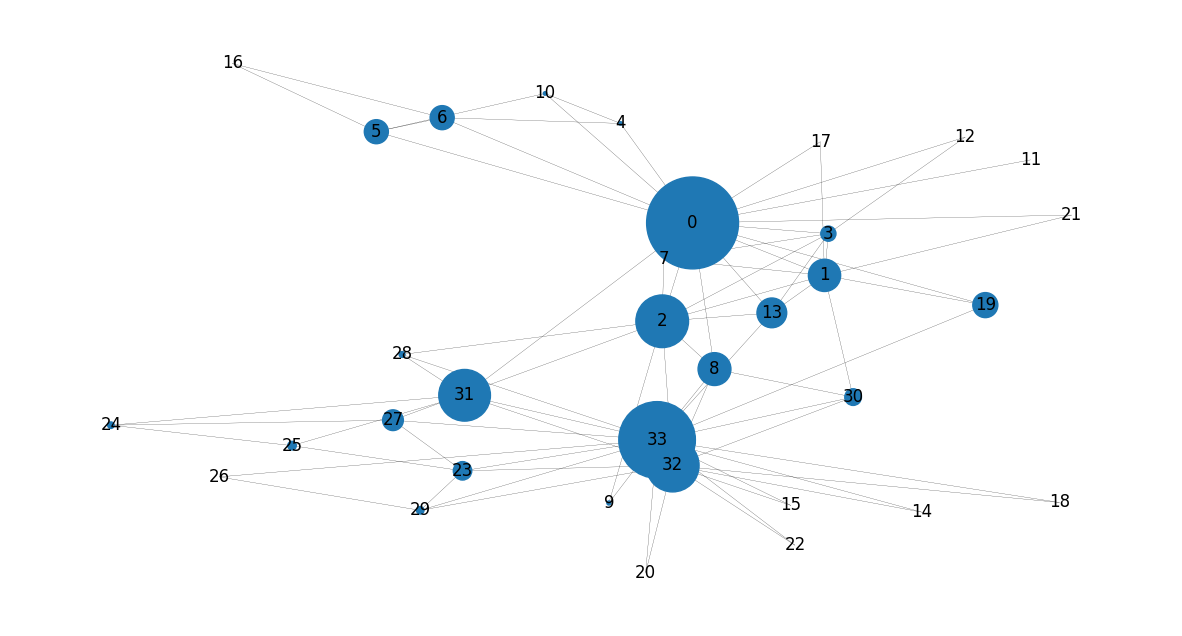

In [35]:
# Визуализация
node_size = [v * 10000 for v in betweenness_centrality.values()]
plt.figure(figsize=(15, 8))
nx.draw_networkx(G, node_size=node_size, with_labels=True, width=0.15)
plt.axis("off")

**Центральность по собственному вектору**

Для неографа центральность по собст. вектору для вершины $i$ равна $i$-тому элементу собственного вектора матрицы смежности, соответствующему максимальному собственному числу $\lambda$.

$$Ax = \lambda x. $$

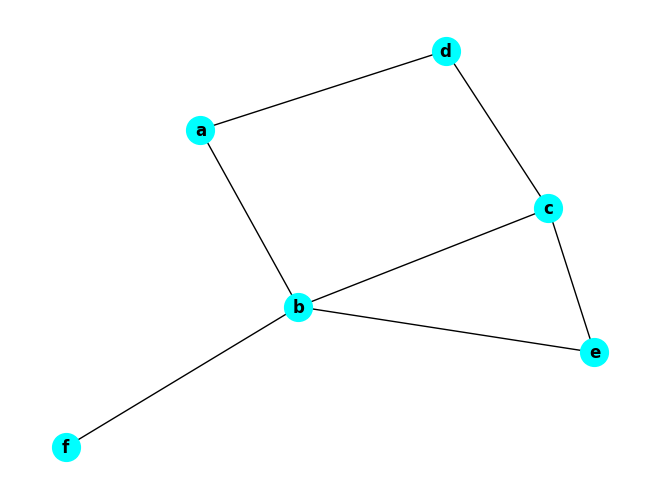

In [36]:
# Граф H

nx.draw(H, node_size=400, node_color='cyan', with_labels=True, font_weight='bold')

In [37]:
nx.centrality.eigenvector_centrality(H)

{'a': 0.3410123357350908,
 'b': 0.563437771403002,
 'd': 0.3228765825656424,
 'c': 0.4981656262056795,
 'e': 0.4084543148167931,
 'f': 0.21678389847563684}

In [38]:
A = nx.adjacency_matrix(H)
print(A)

<Compressed Sparse Row sparse array of dtype 'int64'
	with 14 stored elements and shape (6, 6)>
  Coords	Values
  (0, 1)	1
  (0, 2)	1
  (1, 0)	1
  (1, 3)	1
  (1, 4)	1
  (1, 5)	1
  (2, 0)	1
  (2, 3)	1
  (3, 1)	1
  (3, 2)	1
  (3, 4)	1
  (4, 1)	1
  (4, 3)	1
  (5, 1)	1


In [39]:
# матрица смежности (сразу сохраняем, как не разреженную, чтобы работать с ней)
A = nx.adjacency_matrix(H).todense()
A = np.array(A)  # преобразуем в ndarray
A

array([[0, 1, 1, 0, 0, 0],
       [1, 0, 0, 1, 1, 1],
       [1, 0, 0, 1, 0, 0],
       [0, 1, 1, 0, 1, 0],
       [0, 1, 0, 1, 0, 0],
       [0, 1, 0, 0, 0, 0]])

In [40]:
# собственные числа и вектора A
LA.eig(A)


EigResult(eigenvalues=array([ 2.5990724 , -2.14198709,  0.76610878,  0.46685622, -0.38475265,
       -1.30529766]), eigenvectors=array([[ 0.34101159,  0.46742051,  0.4755164 , -0.43623052, -0.49816569,
         0.02544013],
       [ 0.56343812, -0.5793336 , -0.28960009, -0.2704655 , -0.21678431,
        -0.37801432],
       [ 0.32287568, -0.42187511,  0.65389738,  0.06680856,  0.40845488,
         0.34480738],
       [ 0.49816569,  0.43623052,  0.02544013,  0.46742051,  0.34101159,
        -0.4755164 ],
       [ 0.40845488,  0.06680856, -0.34480738,  0.42187511, -0.32287568,
         0.65389738],
       [ 0.21678431,  0.2704655 , -0.37801432, -0.5793336 ,  0.56343812,
         0.28960009]]))

In [41]:
# максимальный собственный вектор (соответветсвующий максимальному собственному числу)
LA.eig(A)[1][:, 0]

array([0.34101159, 0.56343812, 0.32287568, 0.49816569, 0.40845488,
       0.21678431])

In [42]:
# подсчет итеративным способом

x0 = np.ones(6)/6

for i in range(30):
  x = LA.matrix_power(A, i).dot(x0)
  print(f'Итерация {i}: A^{i}.x{i} = {x/LA.norm(x)}')

Итерация 0: A^0.x0 = [0.40824829 0.40824829 0.40824829 0.40824829 0.40824829 0.40824829]
Итерация 1: A^1.x1 = [0.32444284 0.64888568 0.32444284 0.48666426 0.32444284 0.16222142]
Итерация 2: A^2.x2 = [0.37647348 0.50196464 0.3137279  0.50196464 0.43921906 0.25098232]
Итерация 3: A^3.x3 = [0.31437304 0.60456354 0.33855558 0.48365083 0.38692067 0.19346033]
Итерация 4: A^4.x4 = [0.36314046 0.53074374 0.30727269 0.51212115 0.41900822 0.23278234]
Итерация 5: A^5.x5 = [0.322562   0.58777964 0.33689809 0.483843   0.40141049 0.20428927]
Итерация 6: A^6.x6 = [0.35586308 0.54344983 0.31034571 0.51034628 0.41241497 0.22620754]
Итерация 7: A^7.x7 = [0.32855506 0.57908493 0.33333211 0.48725936 0.40551868 0.20912875]
Итерация 8: A^8.x8 = [0.35109423 0.55043568 0.31392195 0.5071361  0.41032478 0.22282944]
Итерация 9: A^9.x9 = [0.33258908 0.57385763 0.33023141 0.49047459 0.40693437 0.21179763]
Итерация 10: A^10.x10 = [0.34786852 0.5547632  0.31669219 0.50444564 0.40952567 0.22080458]
Итерация 11: A^11.

In [43]:
# Центральность по собственному вектору для графа Карате клуба
eigenvector_centrality = nx.centrality.eigenvector_centrality(G)

(sorted(eigenvector_centrality.items(), key=lambda item: item[1], reverse=True))[:10]

[(33, 0.37337121301323506),
 (0, 0.35548349418519426),
 (2, 0.3171893899684447),
 (32, 0.3086510477336959),
 (1, 0.2659538704545024),
 (8, 0.22740509147166046),
 (13, 0.22646969838808145),
 (3, 0.21117407832057056),
 (31, 0.191036269797917),
 (30, 0.17476027834493088)]

(np.float64(-0.8597350678454966),
 np.float64(1.1767169068993457),
 np.float64(-0.8616698761061714),
 np.float64(0.811467716639301))

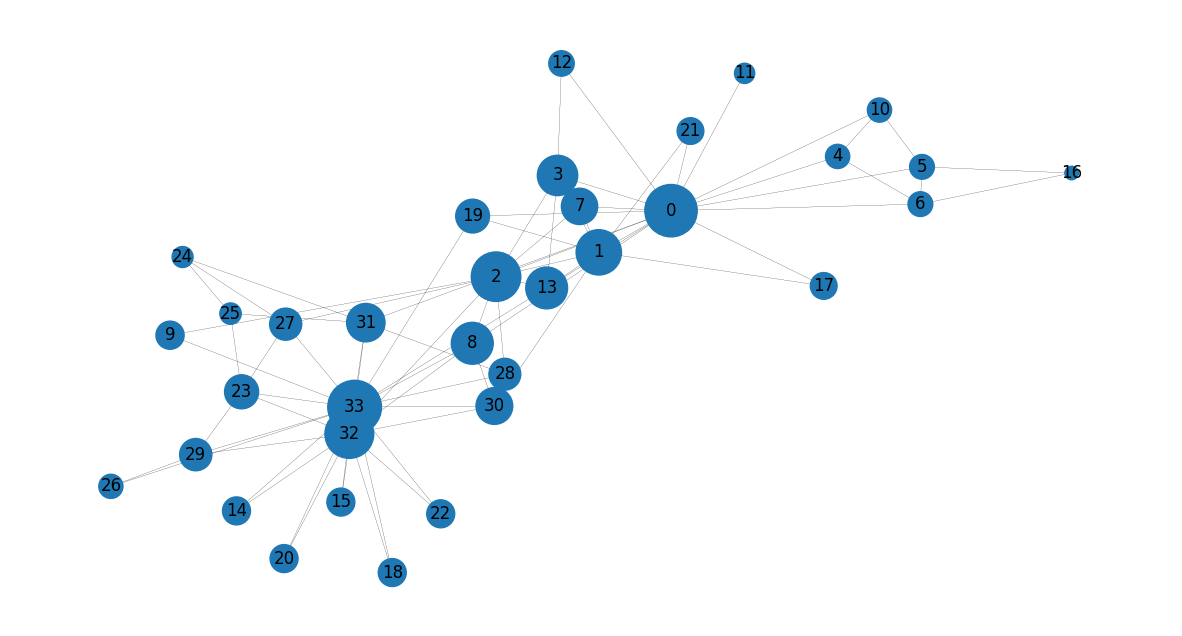

In [44]:
# Визуализация
node_size = [v * 4000 for v in eigenvector_centrality.values()]
plt.figure(figsize=(15, 8))
nx.draw_networkx(G, node_size=node_size, with_labels=True, width=0.15)
plt.axis("off")

## **Задания**

0. Какой(ие) узлы в графе Карате клуба наиболее "важные/влиятельные" и почему ?

In [45]:
print("Top 8 nodes by Degree Centrality:")
print((sorted(degree_centrality.items(), key=lambda item: item[1], reverse=True))[:8])

print("\nTop 8 nodes by Closeness Centrality:")
print((sorted(closeness_centrality.items(), key=lambda item: item[1], reverse=True))[:8])

print("\nTop 8 nodes by Betweenness Centrality:")
print((sorted(betweenness_centrality.items(), key=lambda item: item[1], reverse=True))[:8])

print("\nTop 10 nodes by Eigenvector Centrality:")
print((sorted(eigenvector_centrality.items(), key=lambda item: item[1], reverse=True))[:10])

Top 8 nodes by Degree Centrality:
[(33, 0.5151515151515151), (0, 0.48484848484848486), (32, 0.36363636363636365), (2, 0.30303030303030304), (1, 0.2727272727272727), (3, 0.18181818181818182), (31, 0.18181818181818182), (8, 0.15151515151515152)]

Top 8 nodes by Closeness Centrality:
[(0, 0.5689655172413793), (2, 0.559322033898305), (33, 0.55), (31, 0.5409836065573771), (8, 0.515625), (13, 0.515625), (32, 0.515625), (19, 0.5)]

Top 8 nodes by Betweenness Centrality:
[(0, 0.43763528138528146), (33, 0.30407497594997596), (32, 0.145247113997114), (2, 0.14365680615680618), (31, 0.13827561327561325), (8, 0.05592682780182781), (1, 0.053936688311688304), (13, 0.04586339586339586)]

Top 10 nodes by Eigenvector Centrality:
[(33, 0.37337121301323506), (0, 0.35548349418519426), (2, 0.3171893899684447), (32, 0.3086510477336959), (1, 0.2659538704545024), (8, 0.22740509147166046), (13, 0.22646969838808145), (3, 0.21117407832057056), (31, 0.191036269797917), (30, 0.17476027834493088)]


Центрами конфликта являются точки 33 и 0, по трем метрикам из 4

1. В этом задании используется [датасет обмена эл.письмами](https://networkrepository.com/ia_enron_only.php) в компании Enron с сайта
[Network Repository](https://networkrepository.com).

*   Исследуйте свойства графа (количества вершин, рёбер, плотность графа, диаметр графа, средний клстерный коэффициент)
*   Какие узлы графа можно считать наиболее "важными/влиятельными" и почему?



In [48]:
ia_enron_only = pd.read_csv(
    "ia-enron-only (1).edges",
    sep=" ",
    skiprows=1,  # пропускаем первую строку
    names = ["Unweighted", "undirected"]
)
ia_enron_only

,Unweighted,undirected
0,17,1
1,72,1
2,3,2
3,19,2
4,20,2
...,...,...
618,136,132
619,141,133
620,135,134
621,140,134


In [49]:
G = nx.Graph()
edges = list(zip(ia_enron_only['Unweighted'], ia_enron_only['undirected']))
G.add_edges_from(edges)

In [50]:
num_nodes = G.number_of_nodes()
num_edges = G.number_of_edges()

print(f'Число узлов: {num_nodes}', f'Число ребер: {num_edges}', sep='\n')

Число узлов: 143
Число ребер: 623


In [51]:
G_node_degrees = [degree[1] for degree in G.degree()]
print(f'Минимальная степень узла: {np.min(G_node_degrees)}',
      f'Максимальная степень узла: {np.max(G_node_degrees)}',
      f'Средняя степень узла: {np.mean(G_node_degrees): .6f}', sep='\n')

Минимальная степень узла: 1
Максимальная степень узла: 42
Средняя степень узла:  8.713287


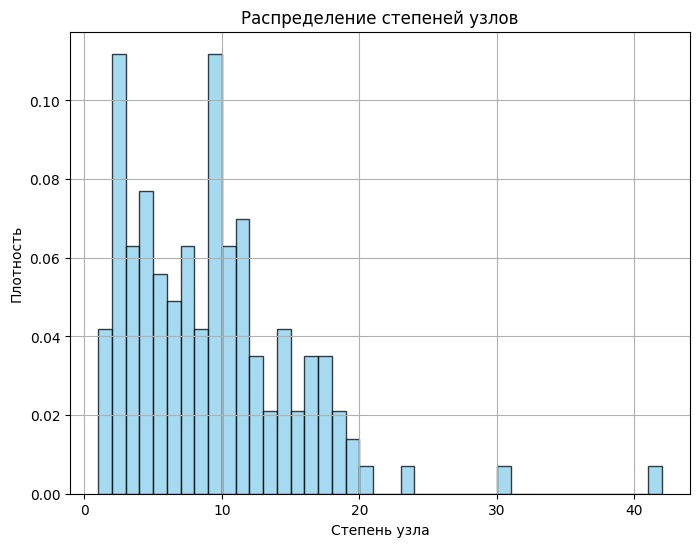

In [52]:
plt.figure(figsize=(8, 6))
plt.hist(G_node_degrees, bins=range(min(G_node_degrees), max(G_node_degrees)+1), density=True, alpha=0.75, color='skyblue', edgecolor='black')
plt.title('Распределение степеней узлов')
plt.xlabel('Степень узла')
plt.ylabel('Плотность')
plt.grid(True)
plt.show()

In [53]:
rad = nx.radius(G)
diam = nx.diameter(G)

print(f'Радиус графа {rad}',
      f'Диаметр графа {diam}',  sep='\n')


Радиус графа 4
Диаметр графа 8


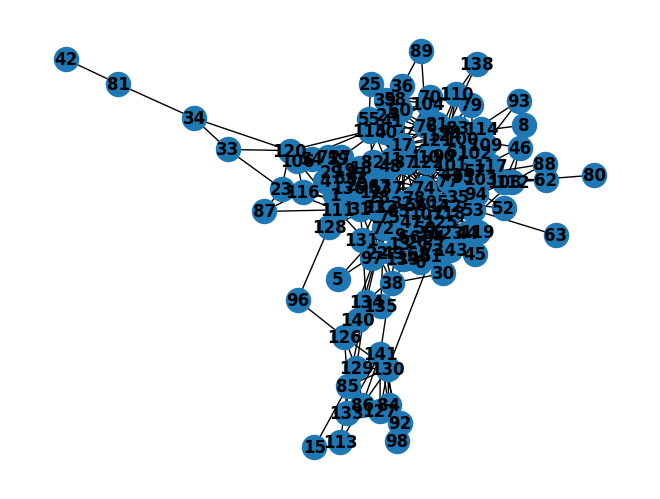

In [54]:
nx.draw(G, with_labels=True, font_weight='bold')


In [55]:
cl_coeff = nx.average_clustering(G)
cl_coeff

0.4339070291479222

In [56]:
degree_centrality = nx.degree_centrality(G)

# сортируем и выводим первые 8
(sorted(degree_centrality.items(), key=lambda item: item[1], reverse=True))[:8]

[(105, 0.29577464788732394),
 (17, 0.2112676056338028),
 (95, 0.1619718309859155),
 (48, 0.14084507042253522),
 (132, 0.13380281690140847),
 (43, 0.13380281690140847),
 (31, 0.1267605633802817),
 (74, 0.1267605633802817)]

(np.float64(-0.664715068813843),
 np.float64(1.1581855947741662),
 np.float64(-0.641507241707648),
 np.float64(0.8266873699271554))

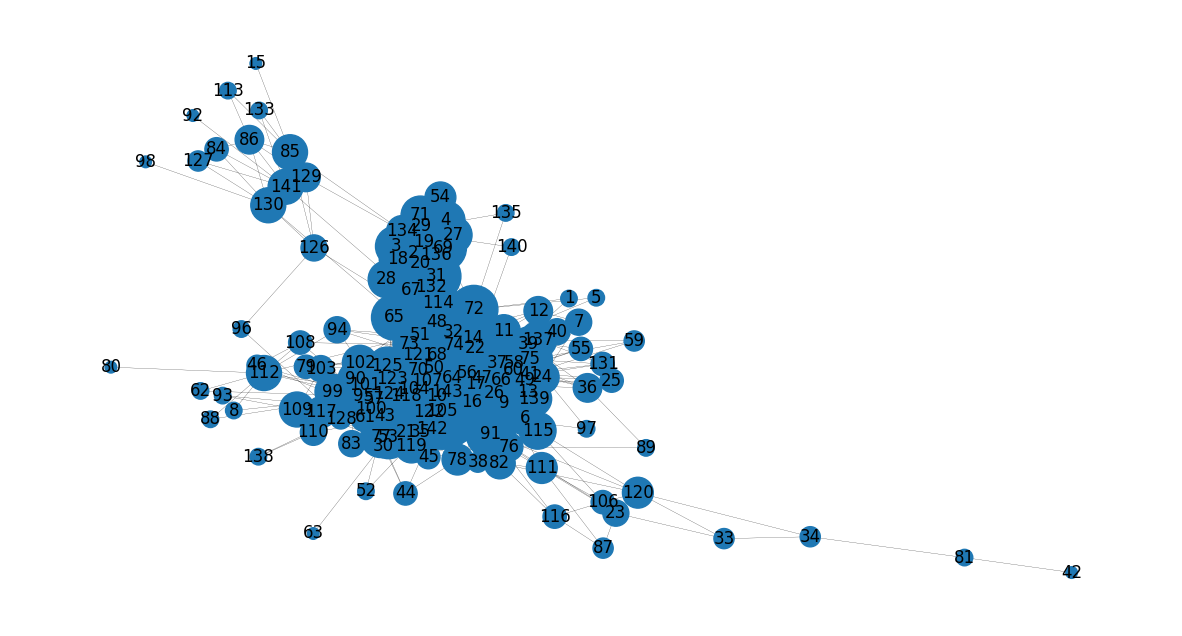

In [57]:
# попытка нарисовать красивую картинку
node_size = [v * 10000 for v in degree_centrality.values()]
plt.figure(figsize=(15, 8))
nx.draw_networkx(G, node_size=node_size, with_labels=True, width=0.15)
plt.axis("off")

In [59]:
degree_centrality = nx.degree_centrality(G)
closeness_centrality = nx.closeness_centrality(G)
betweenness_centrality = nx.betweenness_centrality(G)
eigenvector_centrality = nx.eigenvector_centrality(G)

print("Top 8 nodes by Degree Centrality:")
print((sorted(degree_centrality.items(), key=lambda item: item[1], reverse=True))[:8])

print("\nTop 8 nodes by Closeness Centrality:")
print((sorted(closeness_centrality.items(), key=lambda item: item[1], reverse=True))[:8])

print("\nTop 8 nodes by Betweenness Centrality:")
print((sorted(betweenness_centrality.items(), key=lambda item: item[1], reverse=True))[:8])

print("\nTop 10 nodes by Eigenvector Centrality:")
print((sorted(eigenvector_centrality.items(), key=lambda item: item[1], reverse=True))[:10])


Top 8 nodes by Degree Centrality:
[(105, 0.29577464788732394), (17, 0.2112676056338028), (95, 0.1619718309859155), (48, 0.14084507042253522), (132, 0.13380281690140847), (43, 0.13380281690140847), (31, 0.1267605633802817), (74, 0.1267605633802817)]

Top 8 nodes by Closeness Centrality:
[(105, 0.5), (17, 0.47019867549668876), (95, 0.4382716049382716), (74, 0.4369230769230769), (37, 0.4369230769230769), (48, 0.43558282208588955), (91, 0.43425076452599387), (43, 0.4316109422492401)]

Top 8 nodes by Betweenness Centrality:
[(105, 0.19400604344556296), (17, 0.11088210445609471), (48, 0.09673142009207425), (91, 0.09118959870866389), (32, 0.08554735598477585), (95, 0.07579595400584722), (141, 0.06345441275176905), (22, 0.05846852533268458)]

Top 10 nodes by Eigenvector Centrality:
[(105, 0.2513631026471415), (31, 0.21410710260355367), (136, 0.21070164213770012), (132, 0.2105711443392644), (20, 0.2031133349707531), (19, 0.1986534849023115), (69, 0.1942352880323705), (67, 0.19385055532336717), 

Degree Centrality → кто имеет больше всего связей.

Closeness Centrality → кто ближе всего к остальным узлам (быстро достигает других).

Betweenness Centrality → кто является «мостом» между группами.

Eigenvector Centrality → кто связан с другими влиятельными узлами.

Узел 105 встречается во всех метриках - это самый влиятельный сотрудник.

Узел 17 тоже стабильно попадает в топ по степенной, близости и посредничеству - активный коммуникатор и «мост» между группами.

Узел 48 появляется в трёх метриках (degree, betweenness, eigenvector) - важный посредник и связанный с другими влиятельными узлами.

2. Какие пары узлов в графе Карате клуба имеют наибольшее число общих соседей? Какие пары узлов имеют наибольшую долю общих соседей?

In [77]:
# Наибольшее число общих соседей
max_common = 0
best_pairs = []
for u in G.nodes():
    for v in G.nodes():
        if u < v:
            common = len(list(nx.common_neighbors(G, u, v)))
            if common > max_common:
                max_common = common
                best_pairs = [(u, v)]
            elif common == max_common:
                best_pairs.append((u, v))

print("Пары узлов с наибольшим числом общих соседей:", best_pairs, "=>", max_common)

# Наибольшая доля общих соседей
jaccard = list(nx.jaccard_coefficient(G))
jaccard_sorted = sorted(jaccard, key=lambda x: x[2], reverse=True)
print("Пары узлов с наибольшей долей общих соседей:", jaccard_sorted[:5])


Пары узлов с наибольшим числом общих соседей: [(32, 33)] => 10
Пары узлов с наибольшей долей общих соседей: [(14, 15, 1.0), (14, 18, 1.0), (14, 20, 1.0), (14, 22, 1.0), (15, 18, 1.0)]


Узлы 32 и 33 имеют 10 общих соседей — самые «связанные» узлы, у них больше всего общих соседей. Они являются ядром сообщества.



Пары узлов с наибольшей долей общих соседей (коэффициент Жаккара)

Коэффициент Жаккара равен 1.0, то есть пары узлов имеют полное совпадение соседей.
Узлы 14, 15, 18, 20, 22 — это небольшая группа, где участники имеют одинаковое окружение.

In [78]:
# jaccard_sorted

[(14, 15, 1.0),
 (14, 18, 1.0),
 (14, 20, 1.0),
 (14, 22, 1.0),
 (15, 18, 1.0),
 (15, 20, 1.0),
 (15, 22, 1.0),
 (17, 21, 1.0),
 (18, 20, 1.0),
 (18, 22, 1.0),
 (20, 22, 1.0),
 (7, 13, 0.8),
 (4, 5, 0.75),
 (6, 10, 0.75),
 (9, 28, 0.6666666666666666),
 (17, 19, 0.6666666666666666),
 (19, 21, 0.6666666666666666),
 (13, 19, 0.6),
 (7, 12, 0.5),
 (7, 17, 0.5),
 (7, 21, 0.5),
 (9, 27, 0.5),
 (11, 12, 0.5),
 (11, 17, 0.5),
 (11, 21, 0.5),
 (14, 29, 0.5),
 (14, 30, 0.5),
 (15, 29, 0.5),
 (15, 30, 0.5),
 (18, 29, 0.5),
 (18, 30, 0.5),
 (20, 29, 0.5),
 (20, 30, 0.5),
 (22, 29, 0.5),
 (22, 30, 0.5),
 (8, 13, 0.42857142857142855),
 (7, 19, 0.4),
 (8, 9, 0.4),
 (8, 14, 0.4),
 (8, 15, 0.4),
 (8, 18, 0.4),
 (8, 20, 0.4),
 (8, 22, 0.4),
 (9, 13, 0.4),
 (12, 13, 0.4),
 (13, 17, 0.4),
 (13, 21, 0.4),
 (14, 23, 0.4),
 (15, 23, 0.4),
 (18, 23, 0.4),
 (19, 30, 0.4),
 (20, 23, 0.4),
 (22, 23, 0.4),
 (23, 26, 0.4),
 (25, 27, 0.4),
 (27, 28, 0.4),
 (8, 31, 0.375),
 (23, 31, 0.375),
 (3, 17, 0.33333333333333

3. Для графа H  проверить свойства матрицу Кирхгофа/Лапласа.

In [71]:
# Матрица Лапласа
L = nx.laplacian_matrix(G).todense()

In [72]:
L

array([[42, -4, -5, ..., -2,  0,  0],
       [-4, 29, -6, ...,  0,  0,  0],
       [-5, -6, 33, ...,  0, -2,  0],
       ...,
       [-2,  0,  0, ..., 21, -4, -4],
       [ 0,  0, -2, ..., -4, 38, -5],
       [ 0,  0,  0, ..., -4, -5, 48]])

Матрица симметричная - 1 св-во

In [73]:
eigvals = np.linalg.eigvals(L)
print("Собственные значения матрицы Лапласа:", np.sort(np.real(eigvals)))

Собственные значения матрицы Лапласа: [3.45489264e-15 1.18710730e+00 2.39431926e+00 2.93182048e+00
 2.96830180e+00 3.06104079e+00 3.12126310e+00 3.70606484e+00
 3.80094429e+00 4.16160574e+00 4.54469763e+00 4.69727550e+00
 4.97817925e+00 5.16855490e+00 5.59481244e+00 6.44605541e+00
 6.97788032e+00 9.18096651e+00 1.00106981e+01 1.02218147e+01
 1.18744202e+01 1.20754027e+01 1.43813508e+01 1.48885752e+01
 1.70337951e+01 1.93238240e+01 2.13586504e+01 2.27849630e+01
 2.55555039e+01 2.96883840e+01 3.79927558e+01 4.18328632e+01
 4.59907681e+01 5.20653410e+01]


Все собственные значения положительны - 2 св-во

In [74]:
print("Количество нулевых собственных значений:", np.sum(np.isclose(eigvals, 0)))
print("Число компонент связности графа:", nx.number_connected_components(G))

Количество нулевых собственных значений: 1
Число компонент связности графа: 1


Количество нулевых собственных значений = число компонент связности - 3 св-во

4. Определите главных героев сериала "Игра престолов" в каждом сезоне, опираясь на анализ соответствующих графов. Сравните свои результаты с описанием серий, например, на [7kingdoms](https://7kingdoms.ru/cat/gameofthrones/).

In [79]:
# читаем файл в формате csv
got = pd.read_csv('got-s1-edges.csv', sep=',')

In [80]:
got

,Source,Target,Weight,Season
0,NED,ROBERT,192,1
1,DAENERYS,JORAH,154,1
2,JON,SAM,121,1
3,LITTLEFINGER,NED,107,1
4,NED,VARYS,96,1
...,...,...,...,...
544,SANSA,STANNIS,2,1
545,STANNIS,TOMARD,2,1
546,THEON,WILL,2,1
547,TYRION,TYSHA,2,1


In [85]:
# Создаем граф (взвешенный, так как есть Weight = сила взаимодействия)
G = nx.Graph()
for _, row in got.iterrows():
    G.add_edge(row['Source'], row['Target'], weight=row['Weight'])

In [86]:
degree_centrality = nx.degree_centrality(G)
closeness_centrality = nx.closeness_centrality(G)
betweenness_centrality = nx.betweenness_centrality(G, weight='weight')
eigenvector_centrality = nx.eigenvector_centrality(G, weight='weight')

print("Top 8 nodes by Degree Centrality:")
print(sorted(degree_centrality.items(), key=lambda x: x[1], reverse=True)[:8])

print("\nTop 8 nodes by Closeness Centrality:")
print(sorted(closeness_centrality.items(), key=lambda x: x[1], reverse=True)[:8])

print("\nTop 8 nodes by Betweenness Centrality:")
print(sorted(betweenness_centrality.items(), key=lambda x: x[1], reverse=True)[:8])

print("\nTop 10 nodes by Eigenvector Centrality:")
print(sorted(eigenvector_centrality.items(), key=lambda x: x[1], reverse=True)[:10])


Top 8 nodes by Degree Centrality:
[('NED', 0.456), ('TYRION', 0.328), ('ROBERT', 0.28800000000000003), ('CATELYN', 0.28800000000000003), ('ROBB', 0.24), ('CERSEI', 0.232), ('ARYA', 0.224), ('JOFFREY', 0.216)]

Top 8 nodes by Closeness Centrality:
[('NED', 0.628140703517588), ('ROBERT', 0.5530973451327433), ('CATELYN', 0.5506607929515418), ('TYRION', 0.5434782608695652), ('JON', 0.5186721991701245), ('ROBB', 0.5122950819672131), ('JOFFREY', 0.5102040816326531), ('CERSEI', 0.508130081300813)]

Top 8 nodes by Betweenness Centrality:
[('NED', 0.20550938416422285), ('JORAH', 0.15663912163105712), ('VARYS', 0.09984794023181116), ('TYRION', 0.09905145929339478), ('AERYS', 0.0967754782851557), ('GREATJON_UMBER', 0.08348202764976956), ('ROBERT', 0.07963496951077595), ('JEOR', 0.07428197179164919)]

Top 10 nodes by Eigenvector Centrality:
[('NED', 0.562468715411196), ('ROBERT', 0.3851054478657293), ('CERSEI', 0.28868934342650565), ('LITTLEFINGER', 0.2460995646167414), ('CATELYN', 0.2304254013105

Главные герои сезона 1 — Нед Старк, Роберт, Дейенерис, Джон Сноу, Тирион.


Нед Старк — подтверждается всеми метриками (абсолютный центр).

Роберт — высоко по degree, closeness и eigenvector.

Тирион — высоко по degree, betweenness и closeness.

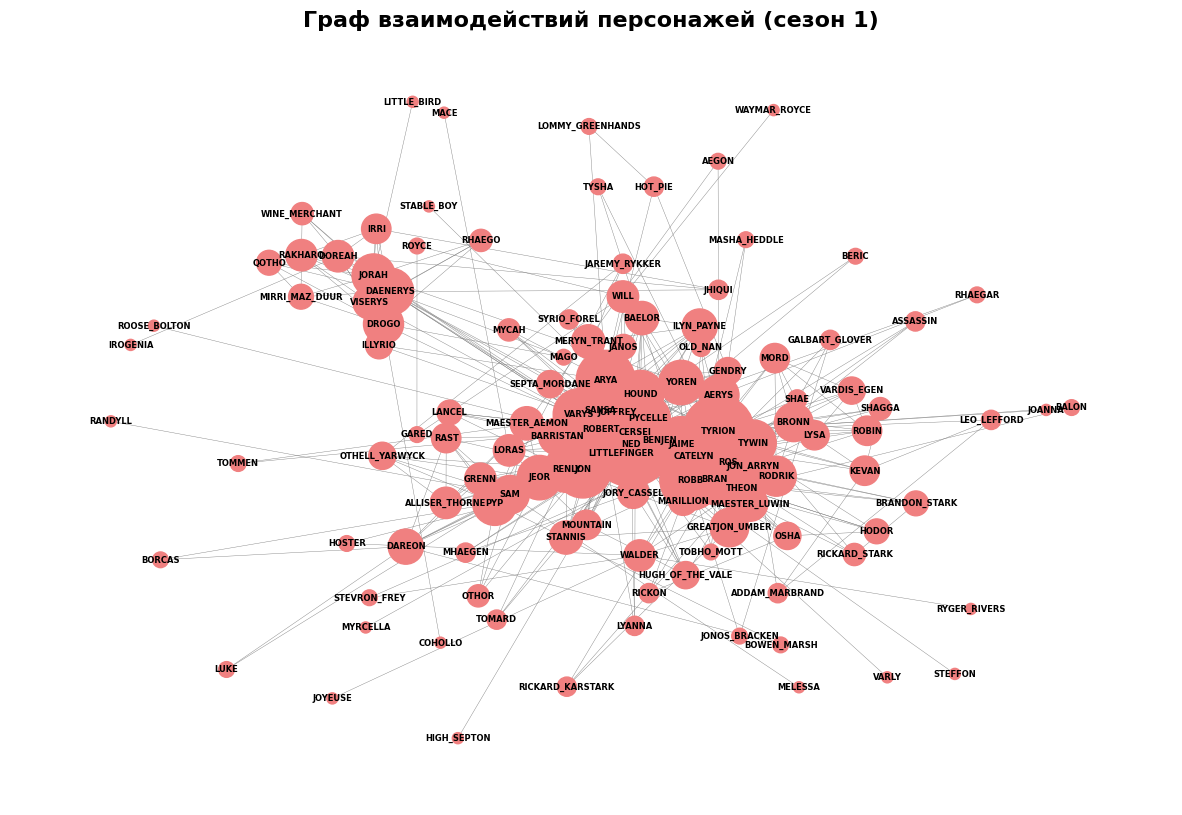

In [94]:
plt.figure(figsize=(15, 10))

# Размер узлов по степенной центральности
node_size = [v * 8000 for v in degree_centrality.values()]

pos = nx.spring_layout(G, k=0.8, iterations=50)  # k=0.8 увеличивает расстояния между точками

nx.draw_networkx(
    G,
    pos=pos,
    node_size=node_size,
    with_labels=True,
    width=0.3,
    node_color="lightcoral",
    font_size=6,
    font_weight="bold",
    edge_color="gray"
)

plt.title("Граф взаимодействий персонажей (сезон 1)", fontsize=16, fontweight="bold")
plt.axis("off")
plt.show()
